In [32]:
from typing_extensions import TypedDict
from langgraph.graph import StateGraph, START, END

from typing import Annotated
from langgraph.graph.message import add_messages

In [33]:
class State(TypedDict):
    messages: Annotated[list, add_messages]

In [34]:
import os
from dotenv import load_dotenv
load_dotenv()

True

In [35]:
from langchain_groq import ChatGroq
llm = ChatGroq(model="openai/gpt-oss-120b", temperature=0.0)
llm.invoke("hello")


AIMessage(content='Hello! How can I assist you today?', additional_kwargs={'reasoning_content': 'The user says "hello". We need to respond appropriately. It\'s a simple greeting. Should respond friendly.'}, response_metadata={'token_usage': {'completion_tokens': 40, 'prompt_tokens': 72, 'total_tokens': 112, 'completion_time': 0.082963662, 'completion_tokens_details': {'reasoning_tokens': 22}, 'prompt_time': 0.003086421, 'prompt_tokens_details': None, 'queue_time': 0.35164948, 'total_time': 0.086050083}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_64b2f1c926', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a196d7-3696-740b-8473-9385a7102c9b-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 72, 'output_tokens': 40, 'total_tokens': 112, 'output_token_details': {'reasoning': 22}})

In [36]:
def superbot(state: State):
    return {"messages" : [llm.invoke(state["messages"])]}

In [37]:
graph = StateGraph(State)

graph.add_node("superbot", superbot)

graph.add_edge(START, "superbot")
graph.add_edge("superbot", END)

graph_builder = graph.compile()

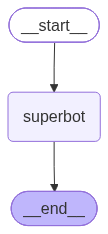

In [38]:
from IPython.display import display, Image

display(Image(graph_builder.get_graph().draw_mermaid_png()))

In [39]:
graph_builder.invoke({
    "messages": "Hello my name is Kiran and I am a data scientist"
})

{'messages': [HumanMessage(content='Hello my name is Kiran and I am a data scientist', additional_kwargs={}, response_metadata={}, id='d57452a4-a1b0-472e-a020-732c34bd2258'),
  AIMessage(content='Hello Kiran! 👋 Great to meet a fellow data scientist. How can I assist you today? Whether you have questions about modeling, data preprocessing, visualization, or anything else, I’m here to help.', additional_kwargs={'reasoning_content': 'The user says "Hello my name is Kiran and I am a data scientist". Likely they are greeting. We should respond politely, maybe ask how can help. No disallowed content. So respond friendly.'}, response_metadata={'token_usage': {'completion_tokens': 96, 'prompt_tokens': 83, 'total_tokens': 179, 'completion_time': 0.199278304, 'completion_tokens_details': {'reasoning_tokens': 44}, 'prompt_time': 0.003771479, 'prompt_tokens_details': None, 'queue_time': 0.392063581, 'total_time': 0.203049783}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_93703442

In [40]:
### stream

In [52]:
for event in graph_builder.stream({"messages": "Write a joke on AI"}):
    messages_ = event["superbot"]
    # print(type(messages_), messages_.keys())
    messages_ = event["superbot"]["messages"]

    for message in messages_:
        print("Content:", message.content)
        print()
        print("ID:", message.id)
        print()
        print("Additional kwargs:", message.additional_kwargs)
        print()
        print("Response metadata:", message.response_metadata)
        print()
        print("Usage metadata:", message.usage_metadata)
        print()
        print("Tool calls:", message.tool_calls)


Content: Why did the AI go to therapy?

Because it kept over‑thinking its *neural* network and couldn't stop *re‑training* its feelings! 😄

ID: lc_run--01a196db-06cc-7409-a0f5-baf63bcdd121-0

Additional kwargs: {'reasoning_content': 'The user asks: "Write a joke on AI". We need to comply. It\'s a simple request, no policy issues. Provide a joke. Should be appropriate.'}

Response metadata: {'token_usage': {'completion_tokens': 76, 'prompt_tokens': 76, 'total_tokens': 152, 'completion_time': 0.157534622, 'completion_tokens_details': {'reasoning_tokens': 34}, 'prompt_time': 0.014362195, 'prompt_tokens_details': None, 'queue_time': 0.352047017, 'total_time': 0.171896817}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_64b2f1c926', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}

Usage metadata: {'input_tokens': 76, 'output_tokens': 76, 'total_tokens': 152, 'output_token_details': {'reasoning': 34}}

Tool calls: []
